## Setup Libraries

In [1]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [2]:
import random
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from importlib.metadata import version
from time import time

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import math
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore')
print("PyTorch  version:", torch.__version__)

pd.set_option('display.max_columns', 100)

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    print('Global seeding seed:', seed)

seed_everything(42)

PyTorch  version: 2.11.0+cu130
Global seeding seed: 42


In [3]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

## Load Data

In [4]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

n_unique = train.nunique().sort_values()
n_unique

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

## Preprocess Features

In [5]:
%%time

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('merchant_category', 'card_type', 'txn_count_last_24h'),
    ('merchant_category', 'customer_age'),
]
def feature_engineering(df, fit=False):
    # Categorize string cats
    for col in cat_cols:
        if fit:
            codes, uniques = df[col].factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = df[col].map(code_map).fillna(-1).astype('int32')
        df[col] = codes
        df[col] = df[col].astype('category')

    # Digit extraction
    digit_config = {'amount_usd': [-3], 'account_balance_usd': [-1]}
    for col, digits_list in digit_config.items():
        for digit in digits_list:
            digit_name = f'{col}_d{digit}_'
            df[digit_name] = (np.floor(df[col] * 10**digit) % 10).astype('int8')
            df[digit_name] = df[digit_name].astype('category')
    
    for col in ['amount_usd', 'hours_since_last_txn',
                'velocity_score', 'distance_from_home_km']:
        decimal_name = f"_{col}_decimal"
        df[decimal_name] = (df[col] % 1).round(2).astype('float32')

    # Categorize numericals
    for col in num_cols + ['_amount_usd_decimal', '_hours_since_last_txn_decimal',
                           '_velocity_score_decimal', '_distance_from_home_km_decimal']:
        cat_name = f"{col}_cat_" if col in num_cols else f"{col[1:]}_cat_"
        values = np.floor(df[col]) if col in num_cols else df[col]
        if fit:
            codes, uniques = values.factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = values.map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')
        
    df = df.drop(['_distance_from_home_km_decimal'], axis=1)

    # Discretize numericals
    bin_config = {'merchant_risk_score': [7], 'hours_since_last_txn': [500, 1000]}
    for col, bins_list in bin_config.items():
        for n_bins in bins_list:
            for strategy in ['quantile']:
                bin_name = f"{col}_{n_bins}_{strategy}_bin_"
                if fit:
                    kb = KBinsDiscretizer(
                        n_bins=n_bins,
                        encode='ordinal',
                        strategy=strategy,
                        subsample=None
                    )
                    binned = kb.fit_transform(df[[col]]).ravel().astype('int32')
                    category_map[bin_name] = kb
                else:
                    kb = category_map[bin_name]
                    binned = kb.transform(df[[col]]).ravel().astype('int32')
                df[bin_name] = binned
                df[bin_name] = df[bin_name].astype('category')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category') 

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")

X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 24
len(new_num_cols): 3 

prep len(cat_cols): 35
prep len(num_cols): 16 

X      prep shape: (699960, 51)
X_test prep shape: (299984, 51) 

CPU times: user 2.77 s, sys: 517 ms, total: 3.29 s
Wall time: 3.31 s


In [12]:
X.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_d-3_,account_balance_usd_d-1_,_amount_usd_decimal,_hours_since_last_txn_decimal,_velocity_score_decimal,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd_decimal_cat_,hours_since_last_txn_decimal_cat_,velocity_score_decimal_cat_,distance_from_home_km_decimal_cat_,merchant_risk_score_7_quantile_bin_,hours_since_last_txn_500_quantile_bin_,hours_since_last_txn_1000_quantile_bin_,merchant_category_card_type_txn_count_last_24h_,merchant_category_customer_age_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,0,0,0,0,0,0,0,0,0,0,0,0,6,0.16,0.77,0.5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,371,553,0,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,1,1,1,1,1,0,0,0,0,0,0,0,3,0.83,0.54,0.4,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,2,80,104,1,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,2,1,0,2,2,0,0,1,0,0,0,0,4,0.36,0.20,0.8,2,1,2,2,2,2,2,0,2,2,2,1,0,2,2,2,2,1,59,79,2,2
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,0,0,2,0,1,0,0,0,0,0,0,0,1,0.44,0.13,0.7,3,2,2,2,0,3,3,0,3,3,0,2,0,3,3,3,3,5,251,338,3,3
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,3,1,2,2,3,0,0,0,0,0,0,0,9,0.85,0.80,0.8,4,3,2,3,3,4,4,0,4,4,3,3,0,4,4,2,4,5,42,54,4,4


## Config

In [13]:
# ── Preprocessing ────────────────────────────────────────────────────────────
class NumericalPreprocessor(BaseEstimator, TransformerMixin):
    """
    Applies a configurable sequence of numerical transforms from CONFIG["tfms"].
    Supported: 'median_center', 'robust_scale', 'smooth_clip', 'l2_normalize'.
    'one_hot' and 'embedding' are recognised but skipped (handled by the model).
    """

    def __init__(self, tfms):
        self._tfms = [t for t in tfms
                      if t in ("median_center", "robust_scale", "smooth_clip", "l2_normalize")]

    def fit(self, X: np.ndarray, y=None):
        if "median_center" in self._tfms or "robust_scale" in self._tfms:
            self._median = np.median(X, axis=0)
            q_diff = np.quantile(X, 0.75, axis=0) - np.quantile(X, 0.25, axis=0)
            zero_idx = q_diff == 0.0
            q_diff[zero_idx] = 0.5 * (X.max(axis=0)[zero_idx] - X.min(axis=0)[zero_idx])
            self._iqr_factors = 1.0 / (q_diff + 1e-30)
            self._iqr_factors[q_diff == 0.0] = 0.0
        return self

    def transform(self, X: np.ndarray, y=None) -> np.ndarray:
        X = X.copy().astype(np.float32)
        for tfm in self._tfms:
            if tfm == "median_center":
                X -= self._median[None, :]
            elif tfm == "robust_scale":
                X *= self._iqr_factors[None, :]
            elif tfm == "smooth_clip":
                X = X / np.sqrt(1 + (X / 3) ** 2)
            elif tfm == "l2_normalize":
                norms = np.linalg.norm(X, axis=1, keepdims=True)
                X /= np.where(norms == 0, 1.0, norms)
        return X

# ── Model components ──────────────────────────────────────────────────────────
class CategoricalFeatureLayer(nn.Module):
    def __init__(self, n_ens: int, cat_dims, embed_dim: int = 8,
                 onehot_thresh: int = 8, device=None):
        super().__init__()
        self.n_ens = n_ens
        self.cat_dims = cat_dims
        self.onehot_features = []
        self.embed_layers = nn.ModuleList()
        self._embed_feature_indices = []

        for i, dim in enumerate(cat_dims):
            if dim <= onehot_thresh:
                self.onehot_features.append(i)
            else:
                emb = nn.ModuleList(
                    [nn.Embedding(dim, embed_dim) for _ in range(n_ens)]
                )
                self.embed_layers.append(emb)
                self._embed_feature_indices.append(i)

    def forward(self, x):
        # x: (batch, n_ens, n_cat)
        batch_size, n_ens, _ = x.shape
        features = []

        if self.onehot_features:
            onehot_x    = x[:, :, self.onehot_features]
            onehot_dims = [self.cat_dims[i] for i in self.onehot_features]
            total_oh    = sum(onehot_dims)
            encoded     = torch.zeros(batch_size, n_ens, total_oh, device=x.device)
            start = 0
            for idx, dim in enumerate(onehot_dims):
                pos = onehot_x[:, :, idx : idx + 1].long()
                encoded.scatter_(2, pos + start, 1.0)
                start += dim
            features.append(encoded)

        for emb_list, feat_idx in zip(self.embed_layers, self._embed_feature_indices):
            feat_embs = []
            for model_idx in range(self.n_ens):
                indices = x[:, model_idx, feat_idx : feat_idx + 1].long()
                feat_embs.append(emb_list[model_idx](indices))    # (batch, 1, embed_dim)
            feat_combined = torch.cat(feat_embs, dim=1)           # (batch, n_ens, embed_dim)
            features.append(feat_combined)

        return torch.cat(features, dim=2)


class ScalingLayer(nn.Module):
    def __init__(self, n_ens: int, n_features: int):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(n_ens, n_features))

    def forward(self, x):
        return x * self.scale[None, :, :]


class NTPLinear(nn.Module):
    def __init__(self, n_ens: int, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        self.in_features  = in_features
        self.out_features = out_features
        self.weight = nn.Parameter(torch.randn(n_ens, in_features, out_features))
        self.bias   = nn.Parameter(torch.randn(n_ens, out_features)) if bias else None

    def forward(self, x):
        # x: (batch, n_ens, in_features)
        # Single einsum replaces transpose → matmul → transpose
        x = torch.einsum("bki,kio->bko", x, self.weight) / math.sqrt(self.in_features)
        if self.bias is not None:
            x = x + self.bias
        return x


class ResidualBlock(nn.Module):
    def __init__(self, n_ens: int, dim: int, dropout: float, activation=nn.SiLU):
        super().__init__()
        self.linear = NTPLinear(
            n_ens=n_ens,
            in_features=dim,
            out_features=dim,
        )
        self.act = activation()
        self.drop = nn.Dropout(dropout)
        # Learnable residual strength
        self.res_scale = nn.Parameter(torch.ones(n_ens, dim) * 0.1)

    def forward(self, x):
        residual = x
        x = self.linear(x)
        x = self.act(x)
        x = self.drop(x)
        return residual + x * self.res_scale.unsqueeze(0)


class PBLDEmbedding(nn.Module):
    """Periodic Basis with Learned Decay embedding for numerical features."""

    def __init__(self, n_ens: int, n_features: int,
                 hidden_dim: int = 16, out_dim: int = 4, freq_scale: float = 0.1,
                 activation=nn.GELU):
        super().__init__()
        self.n_ens      = n_ens
        self.n_features = n_features
        self.out_dim    = out_dim
        self.w1 = nn.Parameter(torch.empty(n_ens, n_features, hidden_dim))
        nn.init.normal_(self.w1, mean=0.0, std=freq_scale / math.sqrt(hidden_dim))
        self.b1 = nn.Parameter(torch.randn(n_ens, n_features, hidden_dim))
        self.w2 = nn.Parameter(
            torch.randn(n_ens, n_features, hidden_dim, out_dim - 1) / math.sqrt(hidden_dim)
        )
        self.b2 = nn.Parameter(torch.zeros(n_ens, n_features, out_dim - 1))
        self.act = activation()
        nn.init.uniform_(self.b1, -math.pi, math.pi)

    def forward(self, x):
        # x: (batch, n_ens, n_features)
        # All operations are fully vectorised over n_features — no Python loop.

        # (batch, n_ens, n_features, 1) * (n_ens, n_features, hidden)
        # → periodic: (batch, n_ens, n_features, hidden)
        periodic = torch.cos(
            2 * math.pi * (
                x.unsqueeze(-1) * self.w1.unsqueeze(0)   # Broadcast over batch
                + self.b1.unsqueeze(0)
            )
        )

        # (batch, n_ens, n_features, hidden) @ (n_ens, n_features, hidden, out-1)
        # → transformed: (batch, n_ens, n_features, out-1)
        transformed = self.act(
            torch.einsum("bkfh,kfhd->bkfd", periodic, self.w2)
            + self.b2.unsqueeze(0)
        )

        # Concatenate raw feature (residual) with transformed output
        # x: (batch, n_ens, n_features) → unsqueeze → (batch, n_ens, n_features, 1)
        feat = torch.cat([x.unsqueeze(-1), transformed], dim=-1)
        # (batch, n_ens, n_features, out_dim) → flatten last two dims
        # → (batch, n_ens, n_features * out_dim)
        return feat.flatten(start_dim=2)

# ── Model ─────────────────────────────────────────────────────────────
class RealMLP(nn.Module):
    def __init__(self, output_dim: int, cat_dims, n_numerical: int, cfg: dict):
        super().__init__()
        n_ens      = cfg["n_ens"]
        embed_dim  = cfg["embed_dim"]
        self.n_ens = n_ens

        self.cate = CategoricalFeatureLayer(
            n_ens=n_ens, cat_dims=cat_dims, embed_dim=embed_dim,
            onehot_thresh=cfg["onehot_thresh"],
        )
        self.num_embed = PBLDEmbedding(
            n_ens=n_ens,
            n_features=n_numerical,
            hidden_dim=cfg["pbld_hidden_dim"],
            out_dim=cfg["pbld_out_dim"],
            freq_scale=cfg["pbld_freq_scale"],
            activation=cfg["pbld_activation"],
        )

        num_emb_dim = n_numerical * cfg["pbld_out_dim"]
        cat_emb_dim = sum(
            c if c <= cfg["onehot_thresh"] else embed_dim for c in cat_dims
        )
        total_dim = num_emb_dim + cat_emb_dim
        hidden_dims = cfg["hidden_dims"]

        act = cfg["activation"]

        # Build layers, tracking which NTPLinear is the "first layer"
        # so we can give it a separate lr group.
        # Each hidden position gets its own Dropout instance (shared instance
        # would only register once in nn.Sequential and break the scheduler).
        self._dropout_modules = []    # Kept for live p_drop_sched updates

        layers = []
        if cfg["add_front_scale"]:
            layers.append(ScalingLayer(n_ens=n_ens, n_features=total_dim))

        in_dim = total_dim
        # First projection layer
        first_linear = NTPLinear(
            n_ens=n_ens,
            in_features=in_dim,
            out_features=hidden_dims[0],
        )
        self.first_linear = first_linear
        layers.extend([first_linear, act()])

        in_dim = hidden_dims[0]
        # Residual blocks
        for hdim in hidden_dims[1:]:
            # Transition layer if dimensions differ
            if in_dim != hdim:
                layers.extend([
                    NTPLinear(
                        n_ens=n_ens,
                        in_features=in_dim,
                        out_features=hdim,
                    ),
                    act(),
                ])
                in_dim = hdim

            block = ResidualBlock(
                n_ens=n_ens,
                dim=hdim,
                dropout=cfg["dropout"],
                activation=act,
            )

            self._dropout_modules.append(block.drop)
            layers.append(block)

        self.hidden = nn.Sequential(*layers)
        self.output_layer = NTPLinear(n_ens=n_ens, in_features=in_dim, out_features=output_dim)

        with torch.no_grad():
            self.output_layer.weight.mul_(0.1)
            if self.output_layer.bias is not None:
                self.output_layer.bias.zero_()

    def forward(self, x_num, x_cat):
        x_num = x_num.unsqueeze(1).expand(-1, self.n_ens, -1)
        x_cat = x_cat.unsqueeze(1).expand(-1, self.n_ens, -1)
        x_num = self.num_embed(x_num)
        x_cat = self.cate(x_cat)
        combined = torch.cat([x_num, x_cat], dim=2)
        x = self.hidden(combined)
        x = self.output_layer(x)
        return x    # (batch, n_ens, 1)

# ── Schedule helpers ─────────────────────────────────────────────────────────
def apply_schedule(init_value: float, progress: float, sched: str,
                   flat_ratio: float = 0.3) -> float:
    """
    Supported schedules:
      'constant'    – no decay
      'cos'         – cosine from init to 0
      'flat_cos'    – flat for flat_ratio, then cosine to 0
      'flat_anneal' – flat for flat_ratio, then linear to 0
      'sqrt_cos'    – sqrt of cosine annealing (slower decay)
      'expm4t'      – exponential decay: init * exp(-4 * progress)
    """
    if sched == "constant":
        return init_value
    elif sched == "cos":
        return init_value * (math.cos(math.pi * progress) + 1) / 2
    elif sched == "flat_cos":
        if progress < flat_ratio:
            return init_value
        t = (progress - flat_ratio) / (1 - flat_ratio)
        return init_value * (math.cos(math.pi * t) + 1) / 2
    elif sched == "flat_anneal":
        if progress < flat_ratio:
            return init_value
        t = (progress - flat_ratio) / (1 - flat_ratio)
        return init_value * (1 - t)
    elif sched == "sqrt_cos":
        return init_value * math.sqrt((math.cos(math.pi * progress) + 1) / 2)
    elif sched == "expm4t":
        return init_value * math.exp(-4 * progress)
    else:
        raise ValueError(f"Unknown schedule: '{sched}'")

# ── Per-parameter-group builder ───────────────────────────────────────────────
def get_parameter_groups(model: RealMLP, p: dict):
    """
    Five groups with independent lr / wd:
      0 – ScalingLayer params  (scale.*)
      1 – PBLD / num_embed params
      2 – first hidden linear weight
      3 – all other weights
      4 – all biases (excluding those already in groups 0-2)
    Note: PBLD has its own bias params (b1, b2) which belong to group 1, not 4.
    The ordering of checks therefore is: scale → num_embed → first_w → bias → other_w.
    """
    first_linear_weight_id = id(model.first_linear.weight)

    scale_p, pbld_p, first_w_p, other_w_p, bias_p = [], [], [], [], []
    for name, param in model.named_parameters():
        if "num_embed" in name:
            # All PBLD params (weights and biases) get their own lr group
            pbld_p.append(param)
        elif "scale" in name:
            scale_p.append(param)
        elif id(param) == first_linear_weight_id:
            first_w_p.append(param)
        elif "bias" in name:
            bias_p.append(param)
        else:
            other_w_p.append(param)

    LR = p["lr"]
    WD = p["weight_decay"]
    return [
        {"params": scale_p,   "lr": LR * p["lr_scale_mult"],         "weight_decay":  WD * p["wd_scale_mult"],         "group": "scale"},
        {"params": pbld_p,    "lr": LR * p["pbld_lr_factor"],        "weight_decay":  WD,                              "group": "pbld"},
        {"params": first_w_p, "lr": LR * p["first_layer_lr_factor"], "weight_decay":  WD * p["first_layer_wd_factor"], "group": "first_w"},
        {"params": other_w_p, "lr": LR,                              "weight_decay":  WD,                              "group": "other_w"},
        {"params": bias_p,    "lr": LR * p["lr_bias_mult"],          "weight_decay":  WD * p["wd_bias_mult"],          "group": "bias"},
    ]

# ── Binary Cross-Entropy Loss with optional class weights ───────
def binary_cross_entropy_loss(
    y_true: torch.Tensor,
    logits: torch.Tensor,
    ls: float = 0.0,
    pos_weight: torch.Tensor = None,
) -> torch.Tensor:
    """
    y_true : (N,) float {0,1}
    logits : (N,) probabilities
    """

    # Binary label smoothing
    if ls > 0.0:
        y_true = y_true * (1.0 - ls) + 0.5 * ls

    if pos_weight is None:
        loss = (
            (1.0 - y_true) * logits
            + F.softplus(-logits)
        )
    else:
        loss = (
            (1.0 - y_true) * logits
            + (1.0 + (pos_weight - 1.0) * y_true)
            * F.softplus(-logits)
        )

    return loss.mean()

# ── Focal Binary Cross-Entropy Loss ───────────────────────────────────────────────────────
def focal_binary_cross_entropy_loss(targets, logits, ls=0.0, gamma=2.0, alpha=0.25):
    # Binary label smoothing
    if ls > 0.0:
        targets = targets * (1.0 - ls) + 0.5 * ls
    
    p = torch.sigmoid(logits)
    bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
    p_t = p * targets + (1 - p) * (1 - targets)
    loss = bce_loss * ((1 - p_t) ** gamma)
    
    if alpha >= 0:
        alpha_t = alpha * targets + (1 - alpha) * (1 - targets)
        loss = alpha_t * loss
        
    return loss.mean()

# ── Sklearn-compatible wrapper ────────────────────────────────────────────────
class RealMLP_TD_Classifier(BaseEstimator):
    """
    Sklearn-compatible wrapper around RealMLP, matching the interface of
    pytabkit's RealMLP_TD_Classifier:
    model = RealMLP_TD_Classifier(**CONFIG)
    model.fit(X_train, y_train, X_val, y_val, cat_col_names=CATS)
    proba = model.predict_proba(X_test)
    """

    def __init__(self, **kwargs):
        # Accept any subset of CONFIG keys; fall back to CONFIG defaults
        self.params = {**CONFIG, **kwargs}

    def fit(self, X_train: pd.DataFrame, y_train, X_val: pd.DataFrame, y_val,
            cat_col_names=None, X_test: pd.DataFrame = None):
        p   = self.params
        dev = torch.device(p["device"] if torch.cuda.is_available() else "cpu")
        verbose = p["verbosity"]
        cat_col_names = cat_col_names or []
        num_col_names = [c for c in X_train.columns if c not in cat_col_names]

        # ── Split num / cat ──────────────────────────────────────────────────
        X_tr_num  = X_train[num_col_names].values.astype(np.float32)
        X_val_num = X_val[num_col_names].values.astype(np.float32)
        X_tr_cat  = X_train[cat_col_names].values.astype(np.int64)
        X_val_cat = X_val[cat_col_names].values.astype(np.int64)
        y_tr      = np.asarray(y_train)
        y_v       = np.asarray(y_val)

        # ── Numerical preprocessing ───────────────────────────────────────────
        self.preprocessor_ = NumericalPreprocessor(p["tfms"])
        self.preprocessor_.fit(X_tr_num)
        X_tr_num  = self.preprocessor_.transform(X_tr_num)
        X_val_num = self.preprocessor_.transform(X_val_num)

        # ── Categorical dims ─────────────────────────────────────────────────────────
        self.cat_col_names_ = cat_col_names
        self.num_col_names_ = num_col_names
        if cat_col_names:
            all_cat = [X_tr_cat, X_val_cat]
            if X_test is not None:
                all_cat.append(X_test[cat_col_names].values.astype(np.int64))
            cat_dims = (np.concatenate(all_cat, axis=0).max(axis=0) + 1).tolist()
        else:
            cat_dims = []
        self.cat_dims_ = cat_dims

        # Clamp indices to [0, dim-1] — -1 codes (unseen pandas categories)
        # wrap to huge ints on GPU and cause device-side assert
        if cat_dims:
            cat_max = np.array(cat_dims) - 1
            X_tr_cat  = np.clip(X_tr_cat,  0, cat_max)
            X_val_cat = np.clip(X_val_cat, 0, cat_max)

        # ── Class weights ────────────────────────────────────────────────────
        classes       = np.unique(y_tr)
        self.classes_ = classes
        weights_np = compute_class_weight(
            class_weight="balanced",
            classes=classes,
            y=y_tr,
        )

        # Sklearn order follows sorted(classes)
        # Class 1 weight becomes BCE positive weight
        pos_weight = torch.tensor(weights_np[1], dtype=torch.float32, device=dev)

        # ── Build model ──────────────────────────────────────────────────────
        self.model_ = RealMLP(
            output_dim=1,
            cat_dims=cat_dims,
            n_numerical=X_tr_num.shape[1],
            cfg=p,
        ).to(dev)

        param_groups = get_parameter_groups(self.model_, p)
        # Store the base lr on each group so the scheduler can scale from it
        for g in param_groups:
            g["lr_base"] = g["lr"]
        optimizer = torch.optim.AdamW(
            param_groups,
            betas=(p["mom"], p["sq_mom"]),
        )

        # ── To tensors ───────────────────────────────────────────────────────
        Xtn = torch.as_tensor(X_tr_num,  dtype=torch.float32, device=dev)
        Xtc = torch.as_tensor(X_tr_cat,  dtype=torch.long,    device=dev)
        ytt = torch.as_tensor(y_tr,      dtype=torch.float32, device=dev)
        Xvn = torch.as_tensor(X_val_num, dtype=torch.float32, device=dev)
        Xvc = torch.as_tensor(X_val_cat, dtype=torch.long,    device=dev)

        n_ens       = p["n_ens"]
        train_bs    = p["train_bs"]
        eval_bs     = p["eval_bs"]
        epochs      = p["epochs"]
        lr_sched    = p["lr_sched"]
        flat_ratio  = p["flat_ratio"]
        ema_decay   = p["ema_decay"]
        total_steps = epochs * len(y_tr)
        train_order = np.arange(len(y_tr))

        best_score      = -np.inf
        best_epoch      = 0
        best_val_probs  = None
        best_state      = None
        ema_state       = None
        if ema_decay > 0:
            ema_state = {k: v.detach().clone() for k, v in self.model_.state_dict().items()}

        # ── Epoch loop ───────────────────────────────────────────────────────
        for epoch in range(epochs):
            self.model_.train()
            for start in range(0, len(y_tr), train_bs):
                progress  = (epoch * len(y_tr) + start) / total_steps
                idx_batch = train_order[start : start + train_bs]

                # Update lr for each param group using its base lr
                for g in optimizer.param_groups:
                    g["lr"] = apply_schedule(g["lr_base"], progress, lr_sched, flat_ratio)

                optimizer.zero_grad()
                y_pred = self.model_(Xtn[idx_batch], Xtc[idx_batch])    # (bs, n_ens, C)

                ls_val   = apply_schedule(p["ls_eps"],  progress, p["ls_eps_sched"],  flat_ratio)
                drop_val = apply_schedule(p["dropout"], progress, p["p_drop_sched"],  flat_ratio)
                for dm in self.model_._dropout_modules:
                    dm.p = drop_val

                loss_1 = binary_cross_entropy_loss(
                    ytt[idx_batch].repeat_interleave(n_ens),
                    y_pred.reshape(-1),
                    ls=ls_val,
                    pos_weight=None,
                )
                loss_2 = focal_binary_cross_entropy_loss(
                    ytt[idx_batch].repeat_interleave(n_ens),
                    y_pred.reshape(-1),
                    ls=ls_val,
                )
                loss = (0.5 * loss_1) + (0.5 * loss_2)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model_.parameters(), p["grad_clip"])
                optimizer.step()

                if ema_state is not None:
                    with torch.no_grad():
                        model_state = self.model_.state_dict()
                        for key, value in model_state.items():
                            if torch.is_floating_point(value):
                                ema_state[key].mul_(ema_decay).add_(value.detach(), alpha=1.0 - ema_decay)
                            else:
                                ema_state[key].copy_(value)

            np.random.shuffle(train_order)

            # ── Validation ───────────────────────────────────────────────────
            self.model_.eval()

            live_state = None
            if ema_state is not None:
                live_state = {k: v.detach().clone() for k, v in self.model_.state_dict().items()}
                self.model_.load_state_dict(ema_state, strict=True)
            
            with torch.no_grad():
                val_probs_pos = np.concatenate([
                    torch.sigmoid(self.model_(Xvn[s : s + eval_bs], Xvc[s : s + eval_bs]))
                        .mean(dim=1)
                        .squeeze(-1)
                        .cpu()
                        .numpy()
                    for s in range(0, len(y_v), eval_bs)
                ], axis=0)

                val_probs = np.stack(
                    [1.0 - val_probs_pos, val_probs_pos],
                    axis=1,
                )

            val_pred = val_probs[:, 1]
            epoch_score = roc_auc_score(y_v, val_pred)
            improved    = epoch_score > best_score
            if improved:
                best_score     = epoch_score
                best_epoch     = epoch + 1
                best_val_probs = val_probs.copy()
                state_src      = ema_state if ema_state is not None else self.model_.state_dict()
                best_state     = {k: v.detach().clone() for k, v in state_src.items()}

            # Restore non-EMA/live weights before continuing training
            if live_state is not None:
                self.model_.load_state_dict(live_state, strict=True)

            if verbose >= 2:
                print(
                    f"  epoch {epoch + 1}/{epochs}  "
                    f"score = {epoch_score:.5f}  "
                    f"best = {best_score:.5f}  "
                    f"ls = {ls_val:.4f}  drop = {drop_val:.4f}"
                    + (" ✓" if improved else "")
                )

            # ── Early stopping ────────────────────────────────────────────────
            if p["use_early_stopping"]:
                patience = (best_epoch * p["early_stopping_multiplicative_patience"]
                            + p["early_stopping_additive_patience"])
                if (epoch + 1) > patience:
                    if verbose >= 1:
                        print(f"  Early stopping at epoch {epoch + 1} "
                              f"(best epoch {best_epoch})")
                    break

        # ── Restore best weights ──────────────────────────────────────────────
        if best_state is not None:
            self.model_.load_state_dict(best_state, strict=True)
            
        self.best_score_     = best_score
        self.best_val_probs_ = best_val_probs
        self._dev            = dev
        if verbose >= 1:
            print(f"  → best score: {best_score:.5f}  (epoch {best_epoch})")
        return self

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        eval_bs = self.params["eval_bs"]
        X_num = self.preprocessor_.transform(
            X[self.num_col_names_].values.astype(np.float32)
        )
        X_cat = X[self.cat_col_names_].values.astype(np.int64)
        # Clamp to valid embedding range — guards against -1 codes (unseen
        # categories in pandas category dtype) which wrap to large ints on GPU
        X_cat = np.clip(X_cat, 0, np.array(self.cat_dims_) - 1)
        Xn = torch.as_tensor(X_num, dtype=torch.float32, device=self._dev)
        Xc = torch.as_tensor(X_cat, dtype=torch.long,    device=self._dev)
        self.model_.eval()
        with torch.no_grad():
            probs_pos = np.concatenate([
                torch.sigmoid(self.model_(Xn[s : s + eval_bs], Xc[s : s + eval_bs]))
                    .mean(dim=1)
                    .squeeze(-1)
                    .cpu()
                    .numpy()
                for s in range(0, len(X_num), eval_bs)
            ], axis=0)

        return np.stack(
            [1.0 - probs_pos, probs_pos],
            axis=1,
        )

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        probs = self.predict_proba(X)[:, 1]
        return self.classes_[(probs >= 0.5).astype(np.int64)]

In [15]:
## ── NB: original parameters ────────────────────────────────────────────────────

CONFIG = {
    # --- Model architecture ---
    "n_ens":         8,                # Number of ensemble members inside one RealMLP
    "embed_dim":     6,                # Embedding dim for high-cardinality categoricals
    "onehot_thresh": 22,               # Categoricals with nunique <= this get one-hot encoded
    "hidden_dims":   [256, 256, 256],  # MLP hidden layer sizes
    "dropout":       0.06,             # Base dropout probability value
    "p_drop_sched":  "expm4t",         # 'expm4t' | 'flat_cos' | 'constant'
    "activation":    nn.SiLU,          # Activation class for MLP layers
    "add_front_scale": True,           # Whether to prepend a ScalingLayer before MLP layers

    # --- PBLD (periodic) embedding for numericals ---
    "pbld_hidden_dim": 20,             # plr_hidden_1 in official pytabkit's API
    "pbld_out_dim":    5,              # plr_hidden_2 + 1 (includes residual raw feature)
    "pbld_freq_scale": 5.0,            # plr_sigma: init std of frequency weights
    "pbld_activation": nn.PReLU,       # plr_act_name: activation inside PBLD
    "pbld_lr_factor":  0.093,          # plr_lr_factor: PBLD param lr = lr * pbld_lr_factor

    # --- Optimizer ---
    "lr":               0.01,          # Base learning rate (weights)
    "mom":              0.9,           # Adam beta1
    "sq_mom":           0.997,         # Adam beta2
    "lr_sched":        "flat_anneal",  # 'flat_cos' | 'flat_anneal' | 'cos' | 'constant'
    "flat_ratio":       0.3,           # Flat fraction for flat_cos / flat_anneal schedules
    "first_layer_lr_factor": 1.2,      # lr multiplier for first MLP layer weights
    "first_layer_wd_factor": 0.1,      # wd multiplier for first MLP layer weights
    "lr_scale_mult":    10.0,          # Scale-layer lr = lr * lr_scale_mult
    "lr_bias_mult":     0.1,           # Bias        lr = lr * lr_bias_mult
    "weight_decay":     0.013,         # Base weight decay (weights)
    "wd_scale_mult":    0.1,           # Scale-layer wd = weight_decay * wd_scale_mult
    "wd_bias_mult":     0.5,           # Bias        wd = weight_decay * wd_bias_mult
    "ema_decay":        0.997875,      # Exponential Moving Average decay of model weights
    "grad_clip":        1.0,           # Graient clipping value

    # --- Label smoothing ---
    "ls_eps":       0.04,   # Base label smoothing epsilon
    "ls_eps_sched": "cos",  # 'cos' | 'sqrt_cos' | 'constant'

    # --- Preprocessing ---
    # Supported tfms (applied in order to numerical features):
    # 'median_center', 'robust_scale', 'smooth_clip', 'l2_normalize'
    # Categorical tfms ('one_hot', 'embedding') are handled separately by the model
    "tfms": ["median_center", "robust_scale", 'smooth_clip'],

    # --- Training loop ---
    "epochs":    2,
    "train_bs":  256,
    "eval_bs":   10240,
    "verbosity": 2,      # 0 = silent, 1 = fold summary only, 2 = per-epoch

    # --- Early stopping ---
    "use_early_stopping":                     False,
    "early_stopping_additive_patience":       10,     # Stop if epoch > best * mult + add
    "early_stopping_multiplicative_patience": 1,

    # --- Device ---
    "device":       "cuda",
    "random_state": 42,
}

CONFIG

{'n_ens': 8,
 'embed_dim': 6,
 'onehot_thresh': 22,
 'hidden_dims': [256, 256, 256],
 'dropout': 0.06,
 'p_drop_sched': 'expm4t',
 'activation': torch.nn.modules.activation.SiLU,
 'add_front_scale': True,
 'pbld_hidden_dim': 20,
 'pbld_out_dim': 5,
 'pbld_freq_scale': 5.0,
 'pbld_activation': torch.nn.modules.activation.PReLU,
 'pbld_lr_factor': 0.093,
 'lr': 0.01,
 'mom': 0.9,
 'sq_mom': 0.997,
 'lr_sched': 'flat_anneal',
 'flat_ratio': 0.3,
 'first_layer_lr_factor': 1.2,
 'first_layer_wd_factor': 0.1,
 'lr_scale_mult': 10.0,
 'lr_bias_mult': 0.1,
 'weight_decay': 0.013,
 'wd_scale_mult': 0.1,
 'wd_bias_mult': 0.5,
 'ema_decay': 0.997875,
 'grad_clip': 1.0,
 'ls_eps': 0.04,
 'ls_eps_sched': 'cos',
 'tfms': ['median_center', 'robust_scale', 'smooth_clip'],
 'epochs': 2,
 'train_bs': 256,
 'eval_bs': 10240,
 'verbosity': 2,
 'use_early_stopping': False,
 'early_stopping_additive_patience': 10,
 'early_stopping_multiplicative_patience': 1,
 'device': 'cuda',
 'random_state': 42}

## Train K-Fold

In [17]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'combo_names' in globals() else False

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = 'torch_RealMLP'
print(f"\n🚀 Training {model_name}_({X.shape[1]}) with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
fold_times = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()  

    print()
    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # -------------------------------------------------------------
    # Target encoding
    if CFG.TE:
        smooth = 'auto'
        te_cols = combo_names + ['hours_since_last_txn']
        TE = TargetEncoder(cv=5, smooth=smooth, shuffle=True, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = combo_names

        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    cat_cols = [col for col in cat_cols if col not in combos_to_drop]

    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    model = RealMLP_TD_Classifier(**CONFIG)
    
    seeder = 42 #+ (fold-1)
    model.random_state = seeder

    model.fit(X_trn, y_trn, X_val, y_val, cat_col_names=cat_cols)

    val_preds = model.best_val_probs_[:, 1]
    fold_test_preds = model.predict_proba(X_tst)[:, 1]

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed = {seeder}, time = {ff}mins ]")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")
for i, s in enumerate(fold_scores, 1):
    print(f" • Fold {i} AUC: {s}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
# fold_results[f'iter'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-------------------------------------------------|")
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-------------------------------------------------|")

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.3g} mins\n")

del X_trn, y_trn


🚀 Training torch_RealMLP_(51) with 5 Folds

### Fold 1/5
train=(559968, 52), valid=(139992, 52)

  epoch 1/2  score = 0.94728  best = 0.94728  ls = 0.0200  drop = 0.0081 ✓
  epoch 2/2  score = 0.95000  best = 0.95000  ls = 0.0000  drop = 0.0011 ✓
  → best score: 0.95000  (epoch 2)
Fold 1 | AUC: 0.95 [ seed = 42, time = 1.82mins ]

### Fold 2/5
  epoch 1/2  score = 0.94911  best = 0.94911  ls = 0.0200  drop = 0.0081 ✓
  epoch 2/2  score = 0.95090  best = 0.95090  ls = 0.0000  drop = 0.0011 ✓
  → best score: 0.95090  (epoch 2)
Fold 2 | AUC: 0.9509 [ seed = 42, time = 1.82mins ]

### Fold 3/5
  epoch 1/2  score = 0.95352  best = 0.95352  ls = 0.0200  drop = 0.0081 ✓
  epoch 2/2  score = 0.95496  best = 0.95496  ls = 0.0000  drop = 0.0011 ✓
  → best score: 0.95496  (epoch 2)
Fold 3 | AUC: 0.95496 [ seed = 42, time = 1.82mins ]

### Fold 4/5
  epoch 1/2  score = 0.94852  best = 0.94852  ls = 0.0200  drop = 0.0081 ✓
  epoch 2/2  score = 0.95035  best = 0.95035  ls = 0.0000  drop = 0.0011 ✓


## Evaluation and Submission

In [18]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-' * 20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-' * 20)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

--------------------
torch_RealMLP(52)_95004
--------------------
9.11 mins



,auc,time(min)
fold 1,0.95000,1.82
fold 2,0.95090,1.82
fold 3,0.95496,1.82
fold 4,0.95035,1.82
fold 5,0.94398,1.80


In [19]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.001014
1,699961,0.000797
2,699962,0.095859
3,699963,0.003252
4,699964,0.002349


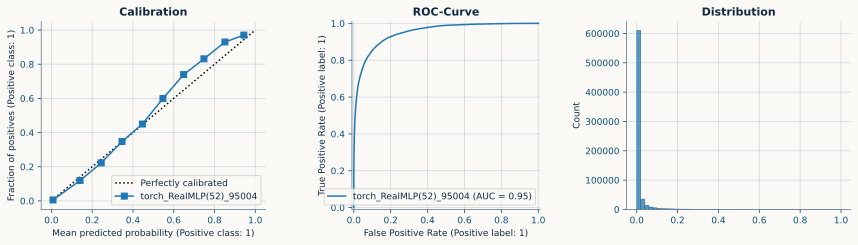

In [20]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 3.5)) 
CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [ ]:
# !rm -r /kaggle/working